# 01 – Exploration des feux de la zone méditerranéenne

**Projet :** *« Quelle est la probabilité qu'un feu démarre dans une commune donnée, un jour donné ? »* — cette fois sur **toute la zone méditerranéenne** (15 départements, ≈ 3 500 communes), et non plus sur les seules Bouches-du-Rhône.

## Leçon 1 – Pourquoi changer d'échelle ?

Dans le projet 13, le modèle apprenait sur **2 480 jours de feu** dans **119 communes**. C'est peu : beaucoup de communes n'avaient brûlé qu'une ou deux fois, et le modèle ne pouvait pas apprendre ce qui distingue une commune à risque d'une autre.

En passant à la zone méditerranéenne :
- on multiplie les exemples de feux par **≈ 6** ;
- on gagne des **paysages très différents** (Corse, Cévennes, Alpes du Sud, littoral varois, plaine languedocienne) → le modèle doit apprendre des règles plus générales ;
- mais la table passe de 434 707 lignes à **≈ 12,8 millions** → il faudra apprendre à **travailler avec des données volumineuses** (formats de fichiers, mémoire, échantillonnage).

## Leçon 2 – Quels départements ?

On prend les **15 départements du dispositif Prométhée**, la base de données historique des feux de forêt méditerranéens, créée en 1973 :

| Région | Départements |
|---|---|
| Provence-Alpes-Côte d'Azur | 04, 05, 06, 13, 83, 84 |
| Occitanie | 11, 30, 34, 48, 66 |
| Auvergne-Rhône-Alpes | 07, 26 |
| Corse | 2A, 2B |

> Même logique qu'en demand planning : avant de modéliser, on regarde **où** et **quand** se concentre la « demande » (ici, les départs de feu).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DEPTS = ["04", "05", "06", "07", "11", "13", "26", "2A", "2B", "30", "34", "48", "66", "83", "84"]

df = pd.read_csv(
    "../data/raw/Incendies.csv", sep=";", skiprows=3, encoding="utf-8",
    dtype={"Département": str, "Code INSEE": str},
)
print(df.shape)   # attendu : (27444, 24) → toute la France, 2016-2025

(27444, 24)


Rappel du projet 13 : les codes département et INSEE doivent être lus **comme du texte** (`dtype=str`), sinon `"06"` devient `6` et `"2A"` fait planter la lecture.

## Étape 1 – Garder les 15 départements

`isin(liste)` renvoie `True` pour les lignes dont la valeur est dans la liste. C'est l'équivalent d'un filtre multi-sélection dans Excel.

In [2]:
feux = df[df["Département"].isin(DEPTS)].copy()
feux["date"] = pd.to_datetime(feux["Date de première alerte"])
feux["surface_ha"] = feux["Surface parcourue (m2)"] / 10_000

print(f"{len(feux)} feux sur {len(df)} en France → {len(feux) / len(df):.0%}")
print("communes touchées :", feux["Code INSEE"].nunique())
print("période :", feux["date"].min().date(), "→", feux["date"].max().date())
print(f"surface brûlée : {feux['surface_ha'].sum():,.0f} ha")

16162 feux sur 27444 en France → 59%
communes touchées : 2621
période : 2016-01-01 → 2025-12-31
surface brûlée : 103,515 ha


**Chiffres attendus :** 16 162 feux (59 % des feux français), 2 621 communes touchées, ≈ 103 500 ha brûlés.

15 départements sur 96 concentrent **près de 6 feux sur 10** : c'est bien la zone où l'outil a le plus de sens.

## Étape 2 – Feux par département

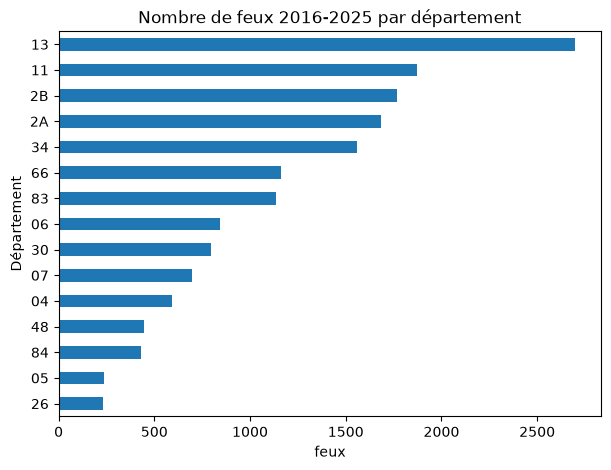

,feux,surface_ha,communes_touchees
Département,,,
13,2699,10873.0,112
11,1874,21031.0,297
2B,1769,16518.0,208
2A,1685,5886.0,118
34,1557,7578.0,275
66,1164,6784.0,185
83,1136,15625.0,149
06,844,3035.0,143
30,797,3825.0,230


In [3]:
par_dept = feux.groupby("Département").agg(
    feux=("Numéro", "size"),
    surface_ha=("surface_ha", "sum"),
    communes_touchees=("Code INSEE", "nunique"),
).sort_values("feux")

par_dept["feux"].plot(kind="barh", figsize=(7, 5), title="Nombre de feux 2016-2025 par département")
plt.xlabel("feux")
plt.show()
par_dept.sort_values("feux", ascending=False).round(0)

**Lecture :** les Bouches-du-Rhône (2 699) restent en tête, suivies de l'Aude, des deux départements corses et de l'Hérault. À l'autre bout, la Drôme et les Hautes-Alpes ont moins de 250 feux en 10 ans.

👉 Le **nombre** de feux et la **surface** brûlée ne racontent pas la même histoire : un département peut avoir peu de feux mais quelques très grands incendies. Notre question porte sur le **départ** de feu (le nombre), pas sur la surface.

## Étape 3 – Saisonnalité

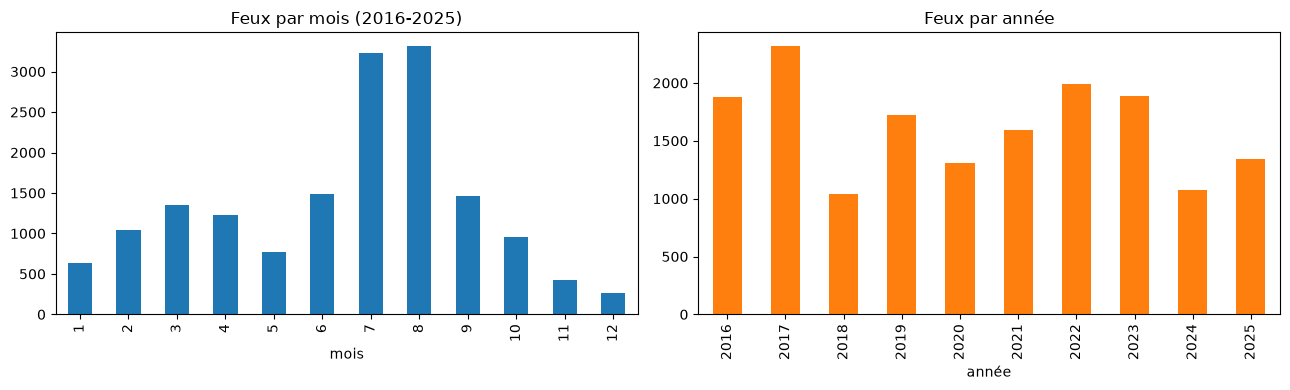

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

feux.groupby(feux["date"].dt.month).size().plot(kind="bar", ax=axes[0], title="Feux par mois (2016-2025)")
axes[0].set_xlabel("mois")

feux.groupby(feux["date"].dt.year).size().plot(kind="bar", ax=axes[1], title="Feux par année", color="tab:orange")
axes[1].set_xlabel("année")

plt.tight_layout()
plt.show()

**Lecture :**
- **Juillet-août** dominent (≈ 3 200-3 300 feux chacun), mais il y a un **second pic en mars-avril** (≈ 1 200-1 350) qu'on ne voyait presque pas dans les Bouches-du-Rhône. Ce sont les feux d'**écobuage** (brûlage de végétation pour entretenir les pâturages), fréquents en montagne en fin d'hiver.
- D'une année à l'autre, ça varie du simple au double : **2017** (2 321 feux) contre **2018** (1 037). La météo de l'année compte énormément.

## Étape 4 – Le profil saisonnier change selon le département

Pour comparer des départements de tailles différentes, on regarde la **part** de leurs feux par mois (chaque ligne fait 100 %). C'est un tableau croisé `crosstab` avec `normalize="index"`.

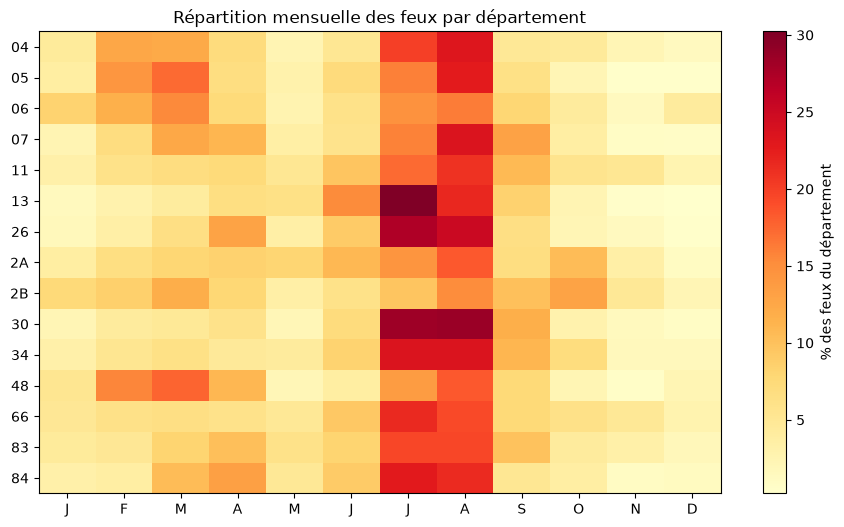

In [5]:
profil = pd.crosstab(feux["Département"], feux["date"].dt.month, normalize="index") * 100

plt.figure(figsize=(11, 6))
plt.imshow(profil, cmap="YlOrRd", aspect="auto")
plt.colorbar(label="% des feux du département")
plt.yticks(range(len(profil)), profil.index)
plt.xticks(range(12), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
plt.title("Répartition mensuelle des feux par département")
plt.show()

**Lecture :** dans les départements de **plaine et du littoral** (13, 30, 34), la moitié des feux tombe en juillet-août et seulement ≈ 15 % en février-avril. Dans les départements de **montagne**, février-avril pèse beaucoup plus : **44 %** en Lozère (48), 37 % dans les Hautes-Alpes (05), ≈ 1/3 dans les Alpes-Maritimes (06), les Alpes-de-Haute-Provence (04) et l'Ardèche (07). La Haute-Corse (2B) est entre les deux, avec des feux répartis sur toute l'année.

👉 Conséquence pour le modèle : *« mois = juillet »* ne suffit pas à dire « risque élevé ». Il faudra croiser saison, géographie et météo. C'est exactement ce que fait un arbre de décision.

## Étape 5 – Les communes les plus touchées

In [6]:
top = (feux.groupby(["Code INSEE", "Nom de la commune", "Département"])
           .size().sort_values(ascending=False).head(15))
top

Code INSEE  Nom de la commune     Département
13056       Martigues             13             224
13001       Aix-en-Provence       13             162
2A247       Porto-Vecchio         2A             140
13047       Istres                13             136
13055       Marseille             13             120
11262       Narbonne              11             108
13071       Les Pennes-Mirabeau   13              87
11069       Carcassonne           11              86
13063       Miramas               13              84
2A362       Zonza                 2A              81
11203       Lézignan-Corbières    11              77
2A004       Ajaccio               2A              77
13005       Aubagne               13              75
13039       Fos-sur-Mer           13              70
13106       Septèmes-les-Vallons  13              69
dtype: int64

## Étape 6 – Les causes (colonne `Nature`)

In [7]:
print(f"Cause renseignée pour {feux['Nature'].notna().mean():.0%} des feux\n")
feux["Nature"].value_counts(normalize=True).mul(100).round(1)

Cause renseignée pour 61% des feux



Nature
Malveillance                  35.5
Involontaire (particulier)    26.8
Involontaire (travaux)        16.0
Accidentelle                  13.5
Naturelle                      8.2
Name: proportion, dtype: float64

La cause n'est connue que pour **61 %** des feux. La **malveillance** (35 %) et les **imprudences** (particuliers 27 %, travaux 16 %) dominent ; les causes naturelles (foudre) ne font que 8 %. Ce sont les **humains qui allument**, et la **météo** qui décide si l'étincelle devient un feu. On ajoutera donc une variable sur la **présence humaine** (population de la commune).

## 🎯 À toi de jouer

1. Quel département a la **plus grande surface brûlée par feu** en moyenne ? (indice : `par_dept["surface_ha"] / par_dept["feux"]`)
2. Quelle part des feux de **Corse** (2A + 2B) a lieu en mars ?

In [8]:
# à toi

<details><summary>Correction</summary>

```python
(par_dept["surface_ha"] / par_dept["feux"]).sort_values(ascending=False).head(3)

corse = feux[feux["Département"].isin(["2A", "2B"])]
(corse["date"].dt.month == 3).mean()
```
</details>

## Récap

1. La zone méditerranéenne (15 départements) concentre **59 %** des feux français : 16 162 feux, 2 621 communes touchées.
2. Deux saisons de feux : l'**été** (sécheresse) partout, et la **fin d'hiver** (écobuage) en montagne et en Corse.
3. Énorme variabilité **d'une année à l'autre** → la météo est clé.
4. Les causes sont surtout **humaines** → on ajoutera la population.

**Prochaine étape (02) :** récupérer les 3 505 communes et construire la grande table *commune × jour*.